# 🏦 Loan Default Prediction using Naïve Bayes



## 🔁 Workflow

```
Load Data → EDA → Preprocessing → Train/Test Split →
Train Model → Evaluate → Visualize Results
```

##  Step 1: Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

##  Step 2: Load the Dataset

In [ ]:
df = pd.read_csv('loan_data (1).csv')
# df.shape
df.isnull().sum()
df.dropna(inplace = True)

##  Step 3: Exploratory Data Analysis (EDA)

<Axes: xlabel='loan_status', ylabel='count'>

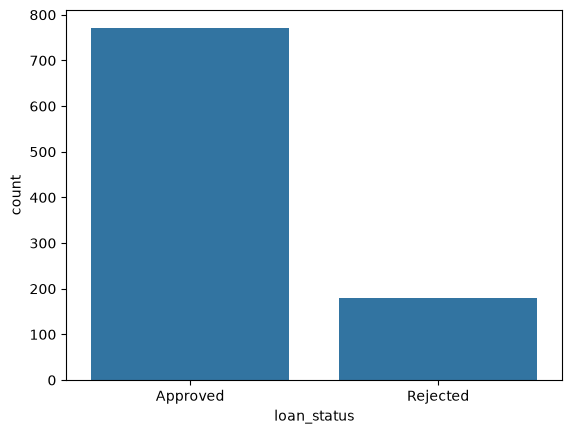

In [ ]:
# Basic info
df.info
df.describe()
df.isnull().sum()

# Target variable distribution
df['loan_status'].value_counts()

# counting for loan status
sns.countplot(data = df, x ='loan_status')

## 🛠️ Step 4: Data Preprocessing

> **Why preprocessing?**  
> Naïve Bayes (GaussianNB) works with **numeric values only**.  
> We need to convert categorical columns (text) into numbers using **Label Encoding/ oneHot Encoding**.

In [4]:
df_copy = df.copy()
df_copy = df_copy.drop('applicant_id', axis = 1)

In [5]:
# Identify categorical columns
cat_col = df_copy.select_dtypes(include='object').columns.drop('loan_status')
cat_col

C:\Users\SHREYASH\AppData\Local\Temp\ipykernel_4212\485544377.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = df_copy.select_dtypes(include='object').columns.drop('loan_status')


Index(['city', 'education', 'employment_type'], dtype='str')

In [6]:
# one hot encoding
df_copy = df.copy()
df_copy = pd.get_dummies(df_copy,
                         columns = cat_col,
                         dtype = int,
                         drop_first= True)
df_copy.head(2)
df_copy.shape

(950, 19)

In [ ]:
df_copy = df_copy.drop('applicant_id', axis = 1)

In [8]:
from sklearn.preprocessing import LabelEncoder

Le = LabelEncoder()
df_copy['loan_status'] = Le.fit_transform(df_copy['loan_status'])
df_copy['loan_status'].head()

0    0
1    1
2    0
3    0
4    0
Name: loan_status, dtype: int64

In [ ]:
# Define Features (X) and Target (y)\
X = df_copy.drop('loan_status', axis = 1)
y = df_copy['loan_status']
X
y

## ✂️ Step 5: Train-Test Split

> We split the data into **80% training** and **20% testing**.  
> The model **learns from training data** and is **evaluated on test data** it has never seen.

In [11]:
# Train-Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

In [12]:
# Perform class imbalance
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=42)
X_train, y_train = sm.fit_resample(X_train, y_train)
X_train.shape, y_train.shape

((1048, 17), (1048,))

## 🤖 Step 6: Train the Naïve Bayes Model

> **GaussianNB** assumes features follow a **Normal (Gaussian) distribution**.  
> It calculates the **mean** and **variance** of each feature for each class.

In [13]:
# Initialize and Train the model
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
gnb.fit(X_train, y_train)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[524.,524.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,154.7
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](17,)","['age','annual_income','loan_amount',...,'employment_type_Freelancer', 'employment_type_Salaried','employment_type_Self-Employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,17
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 17)","[[ 41.06,529674.77,304602.92,..., 0.08, 0.53, 0.25], [ 40.15,564702.48,272274.07,..., 0.01, 0.33, 0.11]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 17)","[[2.89e+02,1.60e+11,6.42e+10,...,1.55e+02,1.55e+02,1.55e+02], [2.38e+02,1.48e+11,3.13e+10,...,1.55e+02,1.55e+02,1.55e+02]]"


In [14]:
y_pred = gnb.predict(X_test)
y_pred[:10]

array([0, 0, 1, 0, 0, 1, 1, 0, 1, 1])

In [15]:
compare = pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : y_pred
})
compare.head(10)

,Actual,Predicted
210,0,0
977,0,0
726,0,1
836,1,0
918,0,0
607,0,1
865,0,1
972,0,0
517,1,1
184,0,1


## 📊 Step 7: Model Evaluation

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import classification_report #does the same work 

print(classification_report(y_test, y_pred))

## 🔮 Step 8: Predict for a New Loan Applicant

> Let's simulate a **real-world prediction** for a new applicant who has **not been seen by the model** before.

In [ ]:
#add some value to make prediction based on them


# KNN

In [17]:
from sklearn.neighbors import KNeighborsClassifier

### Feature Scaling for KNN

> KNN is sensitive to the scale of the features. We need to standardize the features so that all features contribute equally to the distance calculation.

In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit(X_test)

### Train the KNN Model

> We will train a K-Nearest Neighbors classifier on the scaled training data.

In [19]:
# Initialize KNN classifier with n_neighbors (e.g., 5)
neigh = KNeighborsClassifier(n_neighbors=3)
neigh.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### Make Predictions with KNN

In [23]:
y_pred2 = neigh.predict(X_test)
y_pred2[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0])

### Evaluate the KNN Model

> We will evaluate the KNN model using a classification report and confusion matrix to understand its performance.

In [ ]:
#performing the same task

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred2))

              precision    recall  f1-score   support

           0       0.85      0.97      0.91       247
           1       0.76      0.39      0.51        67

    accuracy                           0.84       314
   macro avg       0.81      0.68      0.71       314
weighted avg       0.83      0.84      0.82       314



### Visualize Confusion Matrix for KNN

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

### Elbow Method for Optimal K (K-Means Clustering)



In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Determine a range of K values to test
k_values = range(1, 20) # Testing from 1 to 10 clusters

inertia_values = []

for k in k_values:
    # Ensure X_train_scaled is available and contains your scaled features
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init to suppress warning
    kmeans.fit(X_train_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_values, inertia_values, marker='o', linestyle='-')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(k_values) # Ensure all k_values are shown on x-axis
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()